In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root (notebook is inside notebooks/)
ROOT = Path.cwd().resolve().parent

# Load original data without modifying it
df = pd.read_csv(ROOT / "data" / "raw" / "train.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (1044, 11)


,record_id,date,worker_exp_yr,rain_mm_week,slope_deg,temp_c,bush_age_yr,hours_worked,flush,section,kg_per_worker
0,R00001,2026-01-01,48.0,285,21,15.9,10,5.4,monsoon,River Side,25.5
1,R00002,2026-01-01,132.0,261,18,28.7,13,8.2,monsoon,River Side,33.8
2,R00003,2026-01-01,240.0,149,23,26.7,19,9.7,second,River Side,41.0
3,R00004,2026-01-02,264.0,164,35,23.4,19,4.6,second,River Side,23.1
4,R00005,2026-01-02,6.0,262,8,15.6,57,8.0,second,Upper Garden,33.7


Correlation with target:


kg_per_worker    1.000000
rain_mm_week     0.160238
hours_worked     0.155390
temp_c           0.064010
slope_deg        0.043984
worker_exp_yr   -0.006139
bush_age_yr     -0.094772
Name: kg_per_worker, dtype: float64

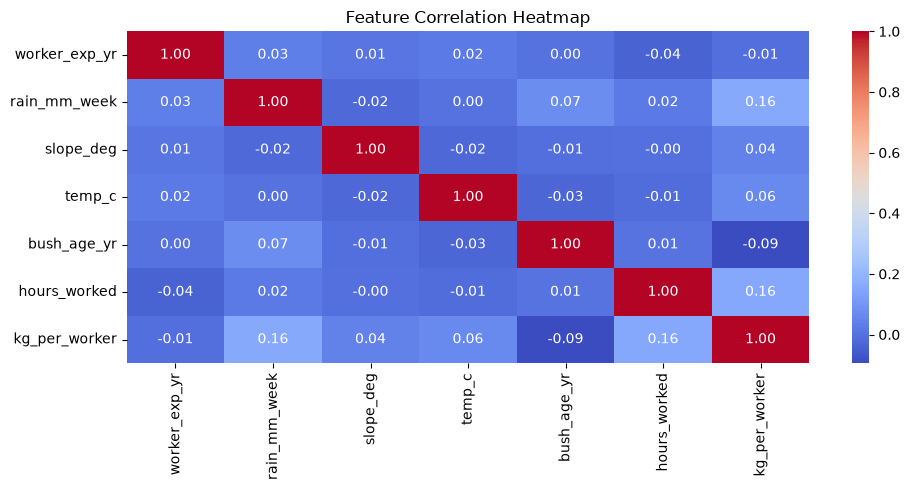

In [3]:

# STEP 2: Data Leakage Investigation

target = "kg_per_worker"

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations with target
correlations = numeric_df.corr()[target].sort_values(
    ascending=False
)

print("Correlation with target:")
display(correlations)

# Visualize correlations
plt.figure(figsize=(10, 5))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [4]:

print("Feature correlations with kg_per_worker:\n")

for feature, value in correlations.items():
    print(f"{feature}: {value:.4f}")


Feature correlations with kg_per_worker:

kg_per_worker: 1.0000
rain_mm_week: 0.1602
hours_worked: 0.1554
temp_c: 0.0640
slope_deg: 0.0440
worker_exp_yr: -0.0061
bush_age_yr: -0.0948


In [5]:

# STEP 4: Check record IDs for duplicates and conflicts

print("Total rows:", len(df))
print("Unique record IDs:", df["record_id"].nunique())
print("Duplicate record IDs:", df["record_id"].duplicated().sum())

# Check whether the same record_id has different data
conflicts = (
    df.groupby("record_id")
      .nunique(dropna=False)
      .drop(columns=["record_id"], errors="ignore")
)

conflicting_ids = conflicts[conflicts.gt(1).any(axis=1)]

print("\nRecord IDs with conflicting values:",
      len(conflicting_ids))

print("\nExamples of repeated record IDs:")
display(
    df[df["record_id"].duplicated(keep=False)]
    .sort_values("record_id")
    .head(15)
)


Total rows: 1044
Unique record IDs: 1000
Duplicate record IDs: 44

Record IDs with conflicting values: 0

Examples of repeated record IDs:


,record_id,date,worker_exp_yr,rain_mm_week,slope_deg,temp_c,bush_age_yr,hours_worked,flush,section,kg_per_worker
10,R00011,2026-01-03,168.0,161,22,11.6,48,8.9,first,River Side,31.8
11,R00011,2026-01-03,168.0,161,22,11.6,48,8.9,first,River Side,31.8
50,R00050,2026-01-11,20.0,17,30,33.1,14,8.6,monsoon,Upper Garden,33.3
51,R00050,2026-01-11,20.0,17,30,33.1,14,8.6,monsoon,Upper Garden,33.3
93,R00092,2026-01-21,28.0,160,20,18.2,59,4.4,first,Upper Garden,26.6
94,R00092,2026-01-21,28.0,160,20,18.2,59,4.4,first,Upper Garden,26.6
116,R00114,2026-01-25,288.0,181,999,21.1,61,7.9,monsoon,River Side,32.6
117,R00114,2026-01-25,288.0,181,999,21.1,61,7.9,monsoon,River Side,32.6
142,R00139,2026-01-31,12.0,86,10,22.1,24,9.4,second,River Side,28.6
143,R00139,2026-01-31,12.0,86,10,22.1,24,9.4,second,River Side,28.6


In [6]:

# STEP 5: Investigate date-related leakage

df_clean = df.drop_duplicates(subset="record_id").copy()

df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    errors="coerce"
)

print("Rows after removing duplicates:", len(df_clean))
print("Earliest date:", df_clean["date"].min())
print("Latest date:", df_clean["date"].max())
print("Invalid dates:", df_clean["date"].isna().sum())

print("\nRecords by year:")
print(df_clean["date"].dt.year.value_counts().sort_index())

print("\nRecords by month:")
print(df_clean["date"].dt.to_period("M").value_counts().sort_index())


Rows after removing duplicates: 1000
Earliest date: 2026-01-01 00:00:00
Latest date: 2026-06-30 00:00:00
Invalid dates: 0

Records by year:
date
2026    1000
Name: count, dtype: int64

Records by month:
date
2026-01    145
2026-02    171
2026-03    199
2026-04    175
2026-05    159
2026-06    151
Freq: M, Name: count, dtype: int64


In [7]:

# STEP 6: Check chronological train-validation split

cutoff = pd.Timestamp("2026-06-01")

train_data = df_clean[
    df_clean["date"] < cutoff
].copy()

val_data = df_clean[
    df_clean["date"] >= cutoff
].copy()

print("Training records:", len(train_data))
print("Validation records:", len(val_data))

print("\nTraining date range:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nValidation date range:")
print(val_data["date"].min(), "to", val_data["date"].max())

print("\nOverlapping record IDs:",
      len(set(train_data["record_id"]) &
          set(val_data["record_id"])))


Training records: 849
Validation records: 151

Training date range:
2026-01-01 00:00:00 to 2026-05-31 00:00:00

Validation date range:
2026-06-01 00:00:00 to 2026-06-30 00:00:00

Overlapping record IDs: 0


In [8]:

# STEP 7: Investigate worker experience unit inconsistencies

exp = df_clean["worker_exp_yr"]

print("Worker experience statistics:")
print(exp.describe())

print("\nValues greater than 50:")
print(exp[exp > 50].value_counts().sort_index())

print("\nNumber of records with experience > 50:",
      (exp > 50).sum())

print("\nExamples of suspicious records:")
display(
    df_clean.loc[
        exp > 50,
        ["record_id", "date", "worker_exp_yr", "kg_per_worker"]
    ].head(20)
)


Worker experience statistics:
count    1000.000000
mean       69.923000
std        96.514632
min         0.000000
25%        12.000000
50%        23.000000
75%        96.000000
max       360.000000
Name: worker_exp_yr, dtype: float64

Values greater than 50:
worker_exp_yr
60.0     13
72.0     11
84.0     17
96.0     12
108.0    10
120.0    10
132.0    17
144.0    12
156.0    12
168.0     9
180.0     8
192.0    10
204.0    19
216.0    10
228.0    11
240.0    12
252.0    13
264.0    13
276.0    10
288.0     7
300.0    11
312.0     9
324.0    10
336.0    11
348.0     9
360.0     6
Name: count, dtype: int64

Number of records with experience > 50: 292

Examples of suspicious records:


,record_id,date,worker_exp_yr,kg_per_worker
1,R00002,2026-01-01,132.0,33.8
2,R00003,2026-01-01,240.0,41.0
3,R00004,2026-01-02,264.0,23.1
6,R00007,2026-01-03,288.0,36.7
7,R00008,2026-01-03,324.0,32.4
10,R00011,2026-01-03,168.0,31.8
12,R00012,2026-01-03,132.0,26.9
15,R00015,2026-01-04,84.0,16.8
17,R00017,2026-01-04,360.0,26.8
24,R00024,2026-01-05,60.0,29.3


In [9]:

# STEP 8: Verify possible months-versus-years issue

exp = df_clean["worker_exp_yr"]

suspicious = exp[exp > 50]

multiples_of_12 = suspicious[
    suspicious % 12 == 0
]

print("Values greater than 50:", len(suspicious))

print("Multiples of 12:", len(multiples_of_12))

print("Non-multiples of 12:",
      len(suspicious) - len(multiples_of_12))

print("\nConverted values (months to years):")
print((multiples_of_12 / 12).describe())

print("\nUnique suspicious values:")
print(sorted(suspicious.unique()))


Values greater than 50: 292
Multiples of 12: 292
Non-multiples of 12: 0

Converted values (months to years):
count    292.000000
mean      16.664384
std        7.338434
min        5.000000
25%       10.750000
50%       17.000000
75%       22.250000
max       30.000000
Name: worker_exp_yr, dtype: float64

Unique suspicious values:
[np.float64(60.0), np.float64(72.0), np.float64(84.0), np.float64(96.0), np.float64(108.0), np.float64(120.0), np.float64(132.0), np.float64(144.0), np.float64(156.0), np.float64(168.0), np.float64(180.0), np.float64(192.0), np.float64(204.0), np.float64(216.0), np.float64(228.0), np.float64(240.0), np.float64(252.0), np.float64(264.0), np.float64(276.0), np.float64(288.0), np.float64(300.0), np.float64(312.0), np.float64(324.0), np.float64(336.0), np.float64(348.0), np.float64(360.0)]


In [10]:

# STEP 9: Test worker experience correction

df_test = df_clean.copy()

mask = (
    (df_test["worker_exp_yr"] > 50) &
    (df_test["worker_exp_yr"] % 12 == 0)
)

df_test.loc[mask, "worker_exp_yr"] = (
    df_test.loc[mask, "worker_exp_yr"] / 12
)

print("Records corrected:", mask.sum())

print("\nBefore correction:")
print(df_clean["worker_exp_yr"].describe())

print("\nAfter correction:")
print(df_test["worker_exp_yr"].describe())

print("\nValues still greater than 50:",
      (df_test["worker_exp_yr"] > 50).sum())


Records corrected: 292

Before correction:
count    1000.000000
mean       69.923000
std        96.514632
min         0.000000
25%        12.000000
50%        23.000000
75%        96.000000
max       360.000000
Name: worker_exp_yr, dtype: float64

After correction:
count    1000.000000
mean       16.397000
std         9.462184
min         0.000000
25%         9.000000
50%        16.500000
75%        24.000000
max        48.000000
Name: worker_exp_yr, dtype: float64

Values still greater than 50: 0


In [11]:

# STEP 10: Investigate invalid slope values

slope = df_clean["slope_deg"]

print("Total records:", len(slope))

print("Records with slope = 999:",
      (slope == 999).sum())

print("Records with slope outside 0-90:",
      ((slope < 0) | (slope > 90)).sum())

print("\nValid slope statistics:")
valid_slope = slope[(slope >= 0) & (slope <= 90)]
print(valid_slope.describe())

print("\nMost common slope values:")
print(slope.value_counts().head(10))


Total records: 1000
Records with slope = 999: 65
Records with slope outside 0-90: 65

Valid slope statistics:
count    935.000000
mean      17.306952
std       10.109831
min        0.000000
25%        8.000000
50%       17.000000
75%       26.000000
max       35.000000
Name: slope_deg, dtype: float64

Most common slope values:
slope_deg
999    65
13     34
20     33
2      32
12     31
1      31
4      31
8      30
22     30
25     30
Name: count, dtype: int64


In [12]:

# STEP 11: Test slope imputation without leakage

train_slope = train_data["slope_deg"].replace(999, np.nan)
val_slope = val_data["slope_deg"].replace(999, np.nan)

# Learn median ONLY from training data
train_median = train_slope.median()

# Apply the same value to both datasets
train_slope_clean = train_slope.fillna(train_median)
val_slope_clean = val_slope.fillna(train_median)

print("Training median slope:", train_median)

print("\nTraining invalid values:",
      train_slope.isna().sum())

print("Validation invalid values:",
      val_slope.isna().sum())

print("\nMissing values after imputation:")
print("Training:", train_slope_clean.isna().sum())
print("Validation:", val_slope_clean.isna().sum())

print("\nTraining slope range:",
      train_slope_clean.min(), "to",
      train_slope_clean.max())

print("Validation slope range:",
      val_slope_clean.min(), "to",
      val_slope_clean.max())


Training median slope: 17.0

Training invalid values: 56
Validation invalid values: 9

Missing values after imputation:
Training: 0
Validation: 0

Training slope range: 0.0 to 35.0
Validation slope range: 1.0 to 35.0


In [13]:

# STEP 12: Investigate target outliers

target = df_clean["kg_per_worker"]

print("Target statistics:")
print(target.describe())

print("\nRecords with yield > 100:",
      (target > 100).sum())

print("\nSuspicious target values:")
print(
    target[target > 100]
    .sort_values()
    .to_string(index=False)
)

print("\nExamples of suspicious records:")
display(
    df_clean.loc[
        target > 100,
        ["record_id", "date", "hours_worked",
         "worker_exp_yr", "kg_per_worker"]
    ].sort_values("kg_per_worker")
)


Target statistics:
count    1000.000000
mean       31.829800
std        32.830216
min         9.800000
25%        23.375000
50%        28.100000
75%        33.200000
max       413.000000
Name: kg_per_worker, dtype: float64

Records with yield > 100: 13

Suspicious target values:
230.0
240.0
253.0
261.0
282.0
292.0
293.0
312.0
330.0
350.0
363.0
365.0
413.0

Examples of suspicious records:


,record_id,date,hours_worked,worker_exp_yr,kg_per_worker
352,R00338,2026-03-03,5.7,18.0,230.0
164,R00160,2026-02-03,4.4,120.0,240.0
1035,R00993,2026-06-29,4.4,23.0,253.0
670,R00645,2026-04-22,4.8,14.0,261.0
76,R00075,2026-01-15,7.1,19.0,282.0
815,R00783,2026-05-18,6.8,6.0,292.0
270,R00262,2026-02-19,6.6,9.0,293.0
855,R00821,2026-05-24,6.7,192.0,312.0
531,R00511,2026-03-31,9.0,204.0,330.0
558,R00537,2026-04-04,7.7,16.0,350.0


In [14]:

# FINAL STEP: Data Quality Summary

from pathlib import Path
import pandas as pd
import numpy as np

# Work on a copy; original CSV remains unchanged
data = df_clean.copy()

# 1. Duplicate records
duplicates = len(df) - len(data)

# 2. Worker experience unit inconsistency
experience_mask = (
    (data["worker_exp_yr"] > 50) &
    (data["worker_exp_yr"] % 12 == 0)
)

# 3. Invalid slope readings
slope_mask = (
    (data["slope_deg"] < 0) |
    (data["slope_deg"] > 90)
)

# 4. Suspicious target values
target_mask = data["kg_per_worker"] > 100

# Test hypothetical decimal correction, without applying it
outliers = data.loc[target_mask, "kg_per_worker"]
hypothetical = outliers / 10

print("=== DATA QUALITY SUMMARY ===")
print("Original records:", len(df))
print("Unique records:", len(data))
print("Duplicate records:", duplicates)
print("Invalid experience units:", experience_mask.sum())
print("Invalid slope values:", slope_mask.sum())
print("Suspicious target values:", target_mask.sum())
print("Invalid dates:", data["date"].isna().sum())

print("\n=== TARGET OUTLIER INVESTIGATION ===")
print("Original suspicious range:",
      outliers.min(), "to", outliers.max())
print("If divided by 10:",
      hypothetical.min(), "to", hypothetical.max())
print("Typical target median:",
      data["kg_per_worker"].median())

print("\n=== DATA SPLIT ===")
print("Training records:", len(train_data))
print("Validation records:", len(val_data))
print("Overlapping IDs:",
      len(set(train_data["record_id"]) &
          set(val_data["record_id"])))

# Save investigation summary
report = pd.DataFrame({
    "Issue": [
        "Duplicate records",
        "Experience unit inconsistency",
        "Invalid slope readings",
        "Suspicious target outliers",
        "Invalid dates"
    ],
    "Affected_Records": [
        duplicates,
        int(experience_mask.sum()),
        int(slope_mask.sum()),
        int(target_mask.sum()),
        int(data["date"].isna().sum())
    ],
    "Proposed_Action": [
        "Remove duplicates before splitting",
        "Convert >50 multiples of 12; document ambiguity",
        "Replace invalid readings and impute from train",
        "Investigate decimal errors; do not auto-correct",
        "No correction required"
    ]
})

report_path = ROOT / "reports"
report_path.mkdir(exist_ok=True)

report.to_csv(
    report_path / "data_quality_summary.csv",
    index=False
)

print("\nSummary saved successfully!")
display(report)


=== DATA QUALITY SUMMARY ===
Original records: 1044
Unique records: 1000
Duplicate records: 44
Invalid experience units: 292
Invalid slope values: 65
Suspicious target values: 13
Invalid dates: 0

=== TARGET OUTLIER INVESTIGATION ===
Original suspicious range: 230.0 to 413.0
If divided by 10: 23.0 to 41.3
Typical target median: 28.1

=== DATA SPLIT ===
Training records: 849
Validation records: 151
Overlapping IDs: 0

Summary saved successfully!


,Issue,Affected_Records,Proposed_Action
0,Duplicate records,44,Remove duplicates before splitting
1,Experience unit inconsistency,292,Convert >50 multiples of 12; document ambiguity
2,Invalid slope readings,65,Replace invalid readings and impute from train
3,Suspicious target outliers,13,Investigate decimal errors; do not auto-correct
4,Invalid dates,0,No correction required
